### Обучение нейронной сети

На практике обучение нейронных сетей (подбор значений весов) производится при помощи **метода градиентного спуска**.

Обучение заключается в **минимизации функции потерь по обучаемым параметрам нейронной сети** — весам и смещениям.

Для минимизации функции потерь методом градиентного спуска **необходимо уметь вычислять градиент функции потерь по всем обучаемым параметрам модели**.

####  Прямое и обратное распространение

Процесс расчета градиента функции потерь по обучаемым параметрам состоит из двух этапов: **прямого и обратного распространения**.

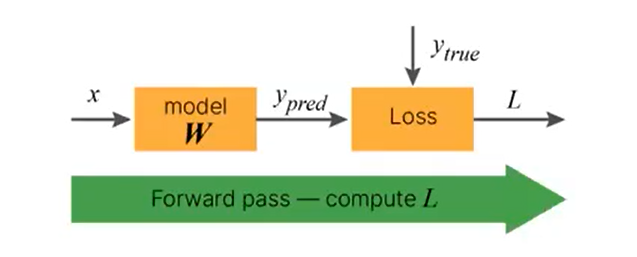

Во время **прямого распространения** (forward pass) производится расчет значений на выходе модели $y_{pred}$, которые передаются в функцию потерь $\text{Loss}$ для сравнения с целевыми значениями $y_{true}$.

$$\large y_{pred}=\text{model}\left(x, 𝐖\right)$$

$$\large L=\text{Loss}\left(y_{true}, y_{pred}\right)$$

Значение функции потерь зависит от целевых значений $y_{true}$, входных данных $x$ и параметров модели $𝐖$.

$$\large L=\text{Loss}\left(y_{true}, \text{model}\left(x, 𝐖\right)\right) = f\left(y_{true}, x, 𝐖\right)$$

А значит, если модель и функция потерь дифференцируемы, мы можем посчитать $\nabla_𝐖L$ — градиент функции потерь по обучаемым параметрам. Для этого нужен этап **обратного распространения** (backward pass).

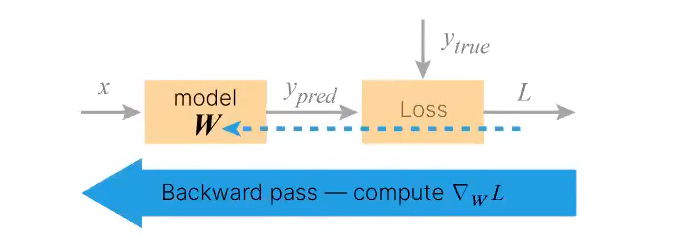

####  Метод обратного распространения ошибки

[Learning Internal Representations by Error Propagation](https://stanford.edu/~jlmcc/papers/PDP/Volume%201/Chap8_PDP86.pdf)

Для эффективного численного расчета градиента функции потерь по обучаемым параметрам модели применяется **метод обратного распространения ошибки (backpropagation)**. Благодаря данному методу становится практически возможным использование метода градиентного спуска для проведения процедуры обучения.

Метод обратного распространения ошибки использует структуру многослойной нейронной сети как сложной функции, применяя **правило дифференцирования сложной функции** для вычисления градиента от функции потерь по весам сети. Градиент от функции потерь вычисляется при движении по нейронной сети от её выходов в направлении входов. Именно такой порядок обхода вычислительного графа и обуславливает название метода.

#### Вычислительный граф

По существу, нейронная сеть является сложной функцией, работу которой можно представить как последовательное выполнение математических операций. Такое представление функций называется **вычислительным графом**.

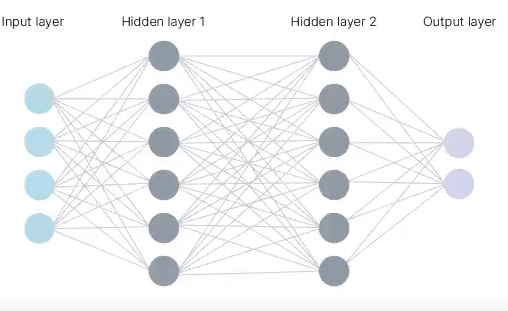

Алгоритм обратного распространения ошибки позволяет находить градиенты для любого графа вычислений, если описываемая им функция дифференцируема.

В его основе лежит правило взятия производной сложной функции (chain rule).

####  Пошаговый разбор метода обратного распространения

Пусть в каком-то узле графа производится вычисление

$$\large z = f(x, y),$$

и далее результат вычисления $\large z$ используется для вычисления функции $\large L(z)=L(f(x, y))$.

Тогда правило вычисления производных $\dfrac{\partial L}{\partial x}$ и $\dfrac{\partial L}{\partial y}$ можно представить следующим образом:

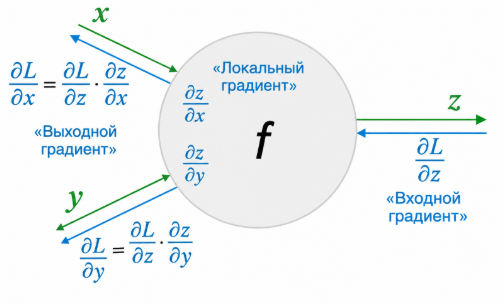

Рассмотрим следующую функцию:

$$\Large f(w,x)=\frac{1}{1+e^{-(w_0x_0+w_1x_1+w_2)}}$$

Представим ее в виде вычислительного графа, состоящего из элементарных операций, от которых просто берутся производные:

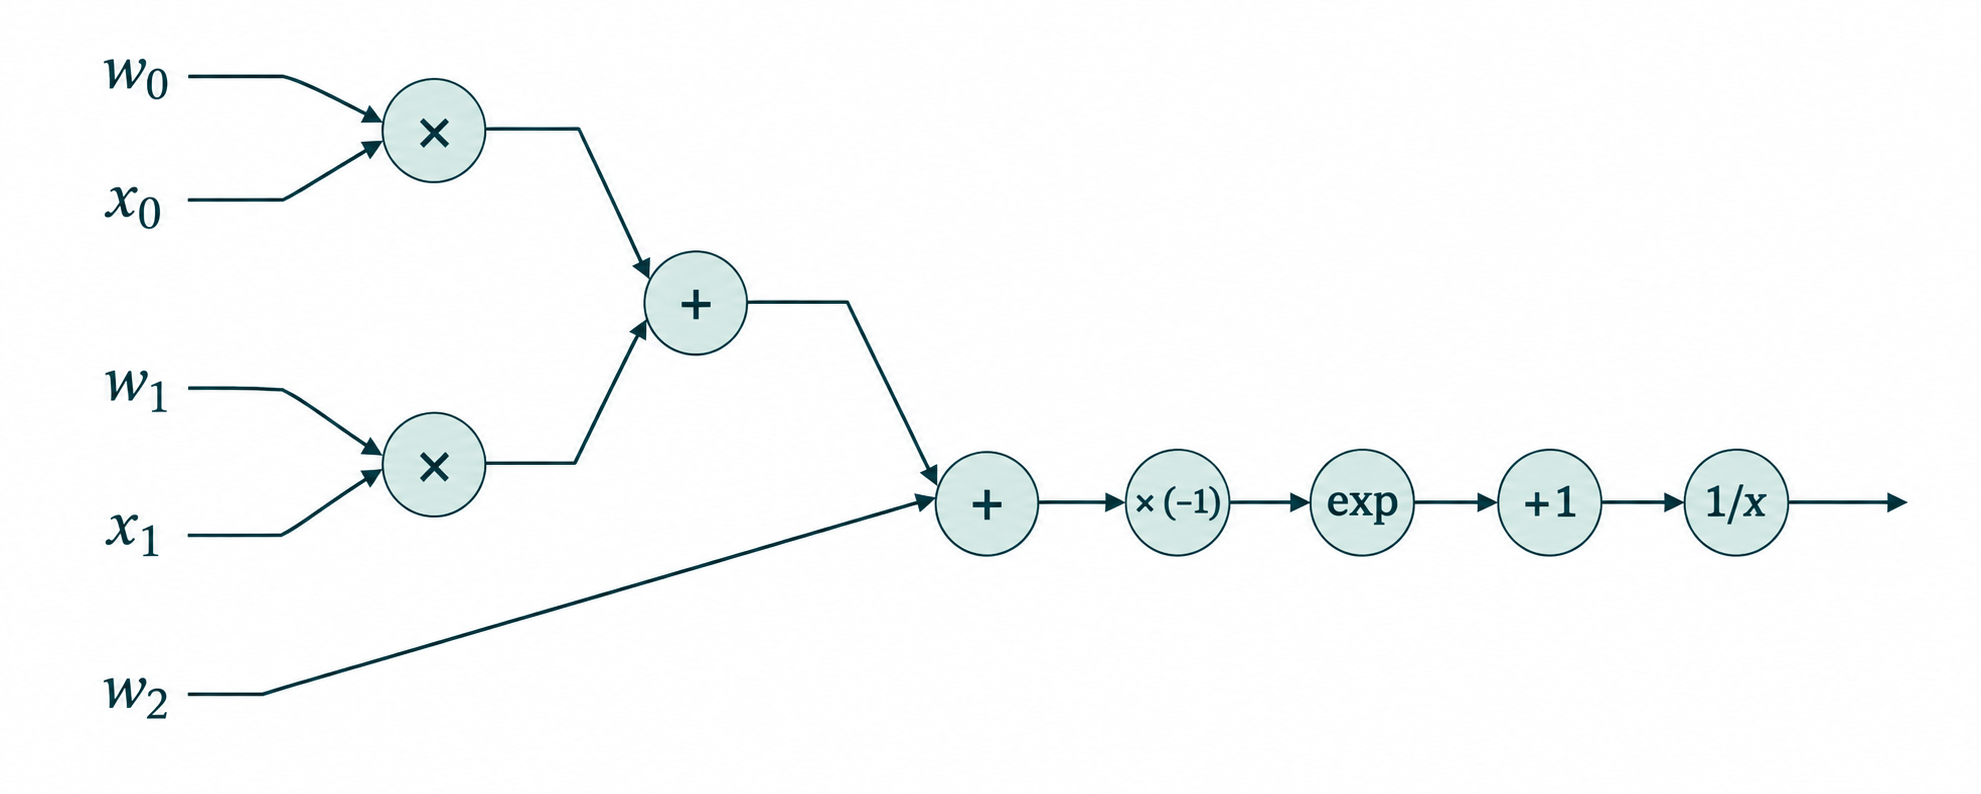

На примере данной функции рассмотрим алгоритм обратного распространения ошибки и найдём величину её градиента по параметрам $\large w$.
Нам потребуется вычислить частные производные $\dfrac{\partial f}{\partial w_0}, \dfrac{\partial f}{\partial w_1}, \dfrac{\partial f}{dw_2}, \dfrac{\partial f}{\partial x_0}$ и $\dfrac{\partial f}{\partial x_1}$.

Пусть "веса" $w$ инициализированы значениями $w_0=2,\;w_1=-3,\;w_2=-3$, а "входные признаки" $x$ принимают значения $x_0=-1,\;x_1=-2$.

Делая прямой проход через граф вычислений для данной функции, получаем её значение для заданных $w$ и $x$ равным $f=0.73$:

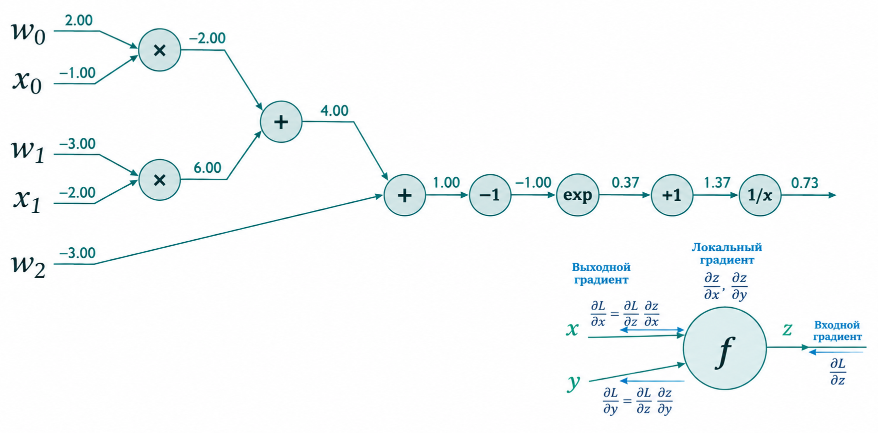

Далее, в соответствии с алгоритмом обратного распространения ошибки, рассчитаем частные производные, пройдясь последовательно по графу вычислений, постепенно накапливая искомое значение для градиента функции.

Для начала зададим $\dfrac{df}{df}=1$.

Начинаем обратный проход по графу вычислений. Первая вершина содержит функцию $f(x)=\dfrac{1}{x}$, производная которой равна $\dfrac{df}{dx}=-\dfrac{1}{x^2}$

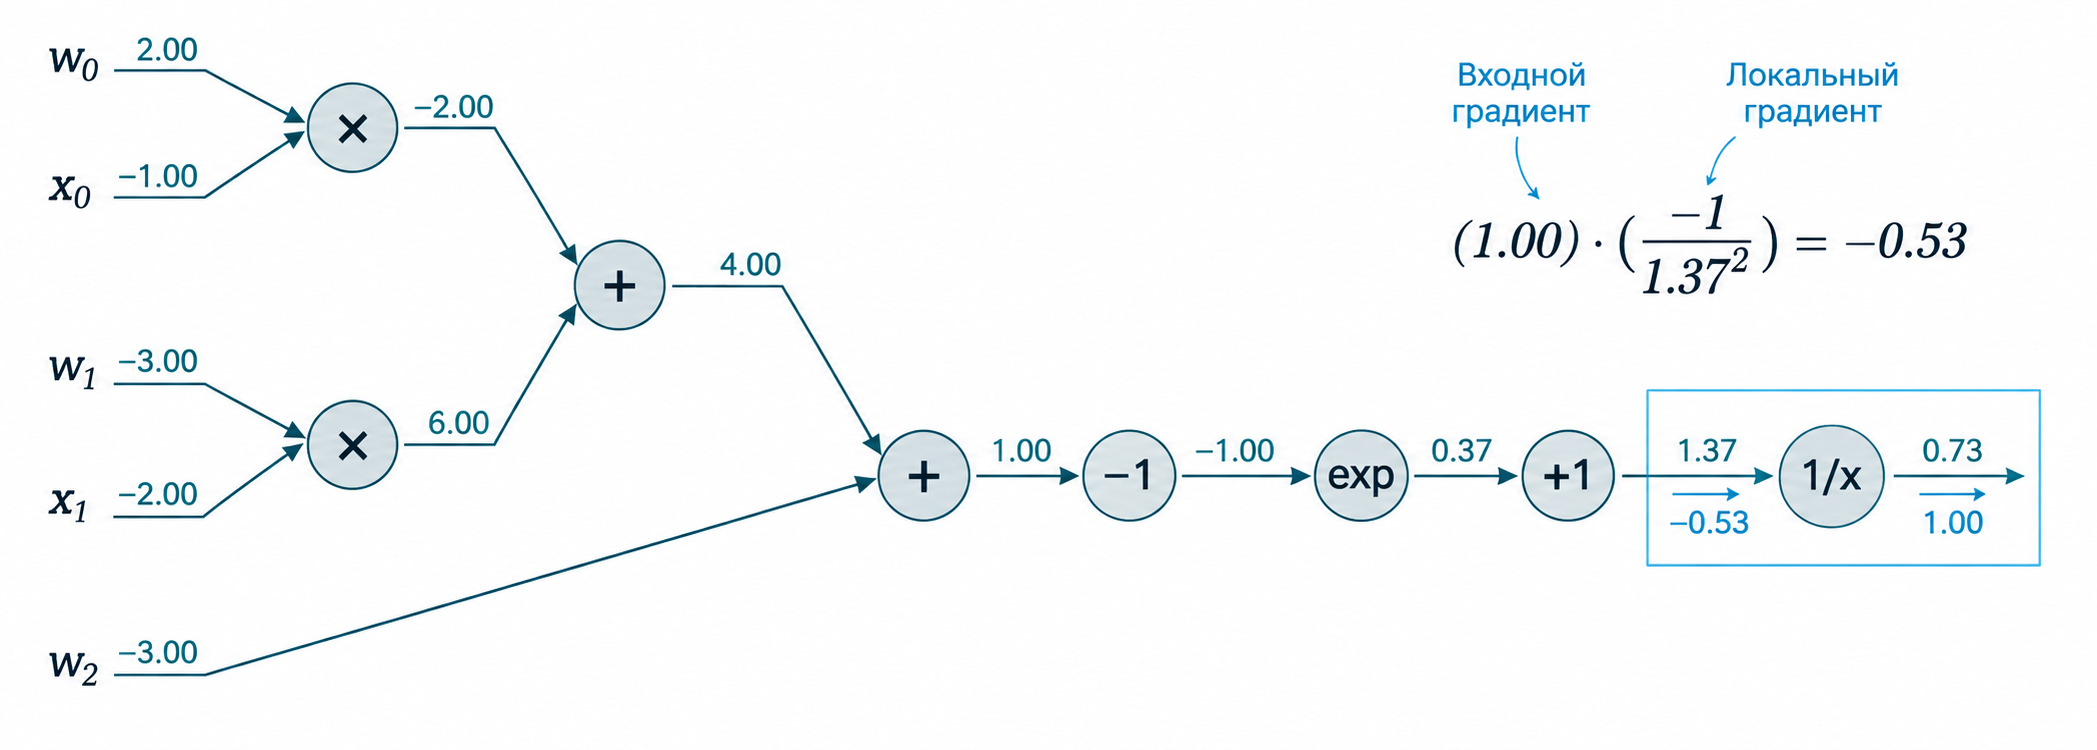

$$\large f(x)=\frac1x \quad \longrightarrow \quad \frac{df}{dx} = -\frac{1}{x^2}$$

В следующем узле находится функция $f(x)=1+x$. Производная от выражения в данном узле равняется $\dfrac{df}{dx}=1$:

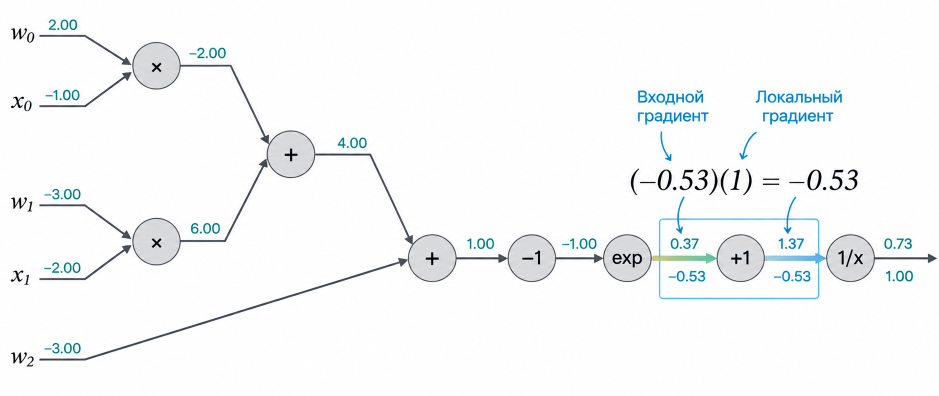

$$\large f(x)=c+x \quad \longrightarrow \quad \frac{df}{dx} = 1$$

Третья вершина содержит экспоненту $f(x)=e^x$. Её производная также является экспонентой $\dfrac{df}{dx}=e^x$:

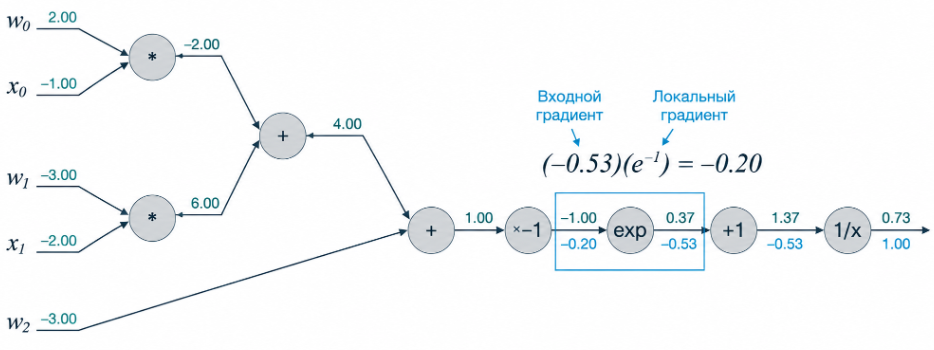


$$\large f(x)=e^x \quad \longrightarrow \quad \frac{df}{dx} = e^x$$

Следующая вершина, четвертая, содержит умножение на константу $f(x)=ax$. Производная равна $\dfrac{df}{dx}=a$ (в данном случае $a=-1$):

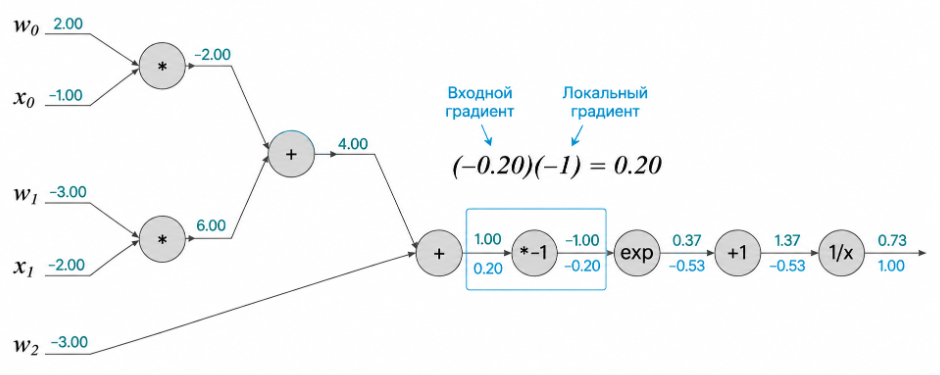

$$\large f(x)=ax \quad \longrightarrow \quad \frac{df}{dx} = a$$

Двигаясь по графу вычислений, мы дошли до узла суммирования, который имеет два входа. Относительно каждого из входов локальный градиент в вершине суммирования будет равен $1$:
$$\large f(x,y)=x+y \quad \Rightarrow \quad \frac{\partial f}{\partial x}=1  \quad \quad \frac{\partial f}{\partial y}=1$$
Так как умножение на единицу не изменит значения входного градиента, всем входам узла суммирования мы можем приписать точно такое же значение входного градиента ($0.2$), что мы имели и для самого узла суммирования. Будем действовать аналогично и со всеми остальными узлами суммирования, которые встретятся нам в вычислительном графе.

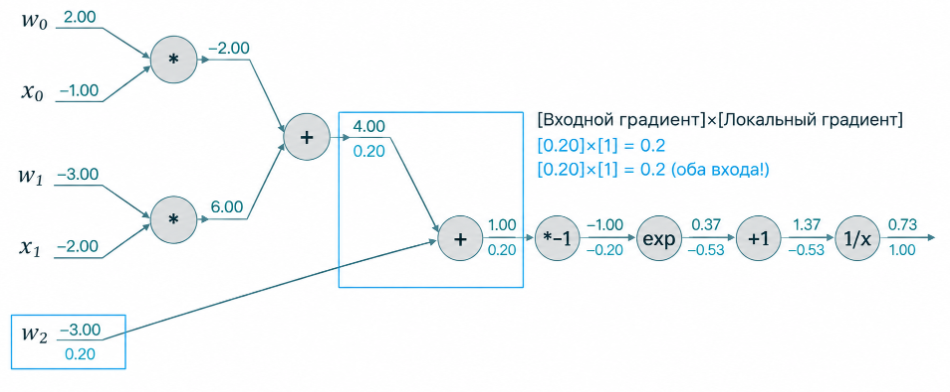

Двигаясь далее к началу графа вычислений, мы подходим к вершинам умножения. Для такой вершины локальный градиент по отношению к какому-либо из входов будет равен значению оставшегося входа. Остается умножить локальный градиент на входящий.

$$\large f(w,x)=wx \quad \Rightarrow \quad \frac{\partial f}{\partial w}=x  \quad \quad \frac{\partial f}{\partial x}=w$$

Точно так же мы можем поступить и с оставшейся второй вершиной умножения, которая привязана к $w_1$ и $x_1$:

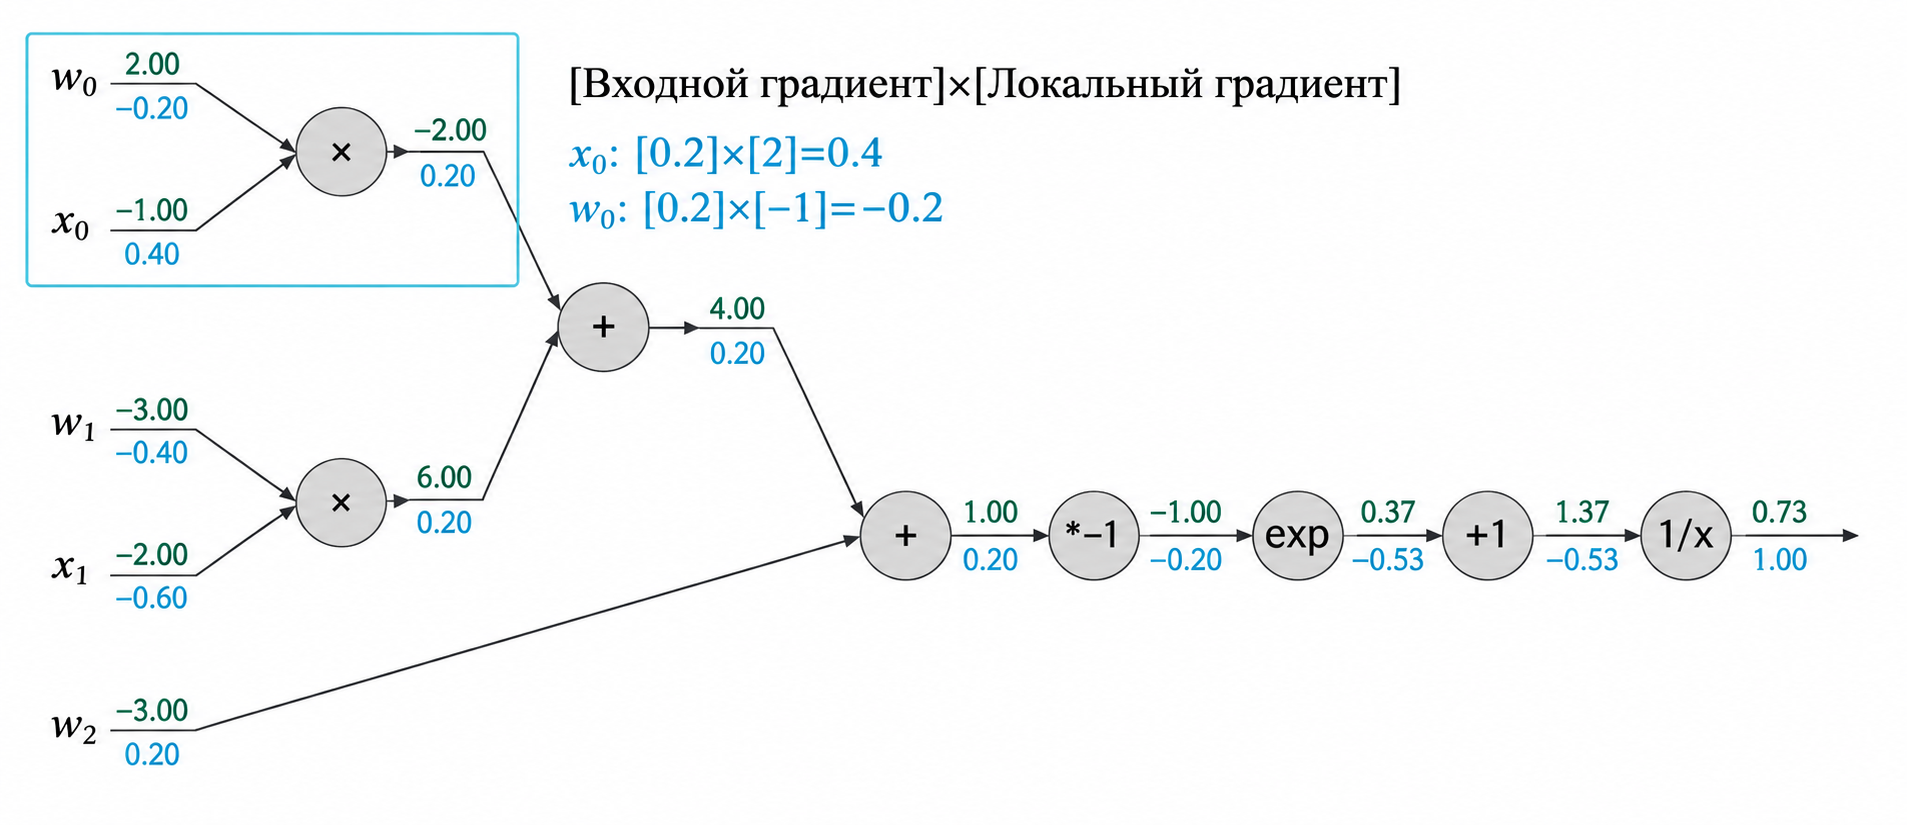

Так, двигаясь по графу вычислений в обратном направлении от выхода функции к входным аргументам, мы последовательно для каждого узла умножаем локальный градиент на входящий градиент, используя цепное правило дифференцирования сложной функции. В описанном примере мы полностью разбили граф вычислений на отдельные элементарные узлы. Разбиение вычислительного графа на элементарные узлы вовсе не обязательно — мы можем сгруппировать несколько вершин вместе, если они образуют дифференцируемую функцию, от которой "удобно" брать производную, и рассматривать их совместно.

В нашем примере мы можем заметить, что вычислительный граф можно свести к двум операциям: получению выражения $w_0x_0+w_1x_1+w_2$ и последующему вычислению от него сигмоидальной функции.

Функция сигмоиды:

$$\large \displaystyle \sigma(x) = \frac{1}{1+e^{-x}}.$$

Важно отметить, что сигмоида обладает важным свойством: её производная может быть выражена через саму сигмоидальную функцию:

$$\large \frac{d}{dx}\sigma(x) = \frac{d}{dx}(1+e^{-x})^{-1} = \frac{e^{-x}}{(1+e^{-x})^{2}} = \frac{1}{1+e^{-x}} \cdot \frac{1+e^{-x}-1}{1+e^{-x}} = \sigma(x)\cdot(1-\sigma(x))$$

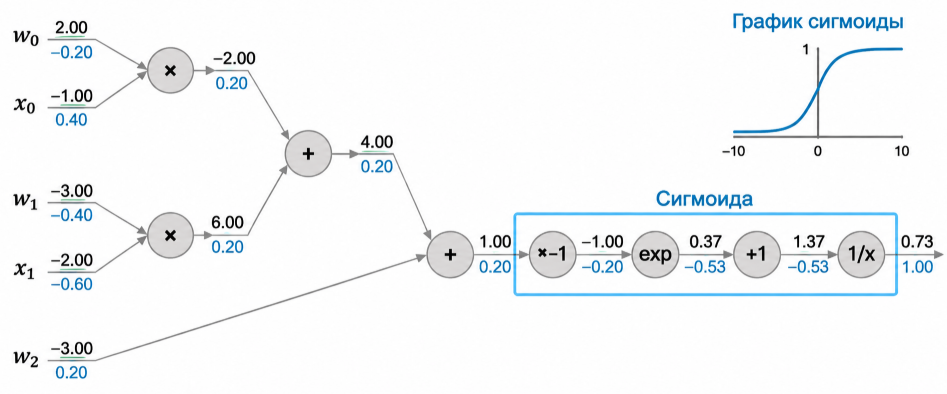